In [5]:

from pathlib import Path
import matplotlib.pyplot as plt

# Get the current working directory
PROJECT_ROOT = Path.cwd().resolve()

# If Jupyter is running inside notebooks/, move to parent
if not (PROJECT_ROOT / "resume_rag.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Verify project directory
assert (PROJECT_ROOT / "resume_rag.py").exists(), (
    f"Project root not found: {PROJECT_ROOT}"
)

# Define results directory
RESULTS_DIR = PROJECT_ROOT / "results"

# Define figures directory
FIGURES_DIR = RESULTS_DIR / "figures"

# Create figures directory if it doesn't exist
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


In [6]:
def save_chart(fig, filename):
    file_path = FIGURES_DIR / filename

    fig.savefig(
        file_path,
        dpi=200,
        bbox_inches="tight"
    )

    print(f"Chart saved successfully: {file_path}")


# RAG-Based Resume Profile Matching
## Experimental Analysis and Performance Evaluation

### Objective

This project evaluates a Retrieval-Augmented Generation
(RAG)-inspired resume matching pipeline that combines
semantic retrieval with rule-based skill filtering and
weighted candidate scoring.

The system:

1. Reads PDF, DOCX, and TXT resumes.
2. Extracts candidate metadata.
3. Splits resumes into section-aware chunks.
4. Generates HuggingFace sentence embeddings.
5. Stores resume chunks in ChromaDB.
6. Retrieves semantically relevant candidates.
7. Applies mandatory skill and experience requirements.
8. Produces ranked candidates with explainable scores.

### Experimental Questions

- How effectively does semantic retrieval identify relevant resumes?
- Does hybrid matching improve ranking quality?
- How does chunking affect the representation of resumes?
- What is the system's retrieval latency?
- What are the major failure modes and limitations?

### Dataset

- 35 fictional candidate resumes
- 15 PDF, 10 DOCX, and 10 TXT documents
- 7 technical role categories
- 5 job descriptions
- 175 candidate-job relevance judgments

### Evaluation Metrics

Precision@5, Precision@10, Recall@5, Recall@10,
Hit Rate@5, Hit Rate@10, MRR, and query latency.


In [7]:

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "resume_rag.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "resume_rag.py").exists(), (
    "Cannot locate project root."
)

sys.path.insert(0, str(PROJECT_ROOT))

DATASET_DIR = PROJECT_ROOT / "dataset"
RESULTS_DIR = PROJECT_ROOT / "results"

def read_json(path):
    with path.open(encoding="utf-8") as file:
        return json.load(file)

candidates = read_json(DATASET_DIR / "candidates.json")
jobs = read_json(DATASET_DIR / "job_descriptions.json")
labels = read_json(DATASET_DIR / "relevance_labels.json")

print("Project:", PROJECT_ROOT)
print("Candidates:", len(candidates))
print("Jobs:", len(jobs))
print(
    "Ground-truth judgments:",
    sum(len(item["judgments"]) for item in labels.values())
)


Project: E:\RAG_Profile_Matching
Candidates: 35
Jobs: 5
Ground-truth judgments: 175


Dataset validation passed.


,candidate_id,candidate_name,role,experience_years,skill_count,file_type
0,C001,Aarav Rao,Python Backend Developer,2,5,.pdf
1,C002,Ananya Singh,Python Backend Developer,4,6,.pdf
2,C003,Rohan Joshi,Python Backend Developer,6,7,.pdf
3,C004,Priya Gupta,Python Backend Developer,8,7,.pdf
4,C005,Kabir Mehta,Python Backend Developer,10,8,.pdf
5,C006,Meera Patel,Frontend Developer,2,6,.pdf
6,C007,Aditya Verma,Frontend Developer,4,7,.pdf
7,C008,Sneha Kapoor,Frontend Developer,6,8,.pdf
8,C009,Arjun Nair,Frontend Developer,8,8,.pdf
9,C010,Isha Sharma,Frontend Developer,10,9,.pdf


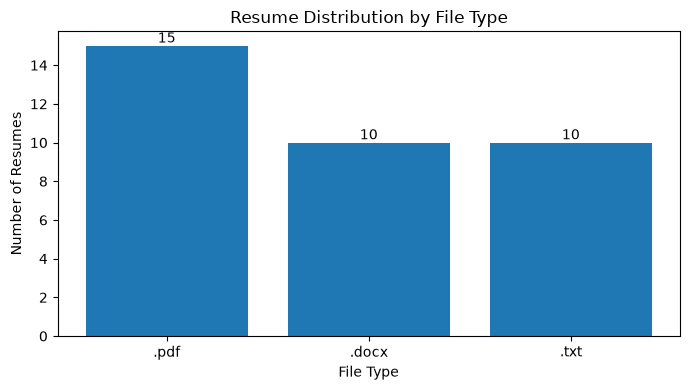

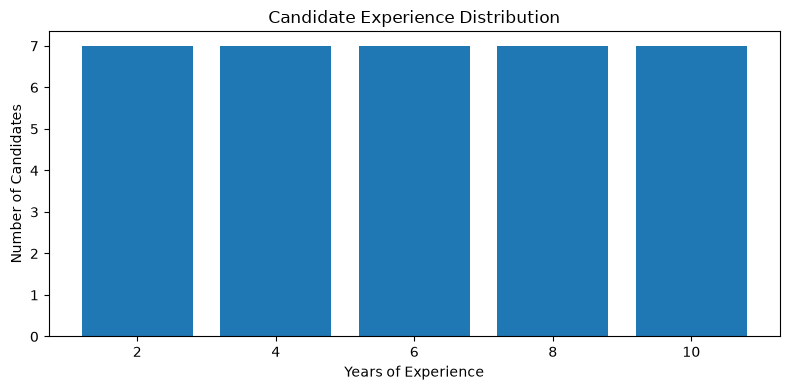

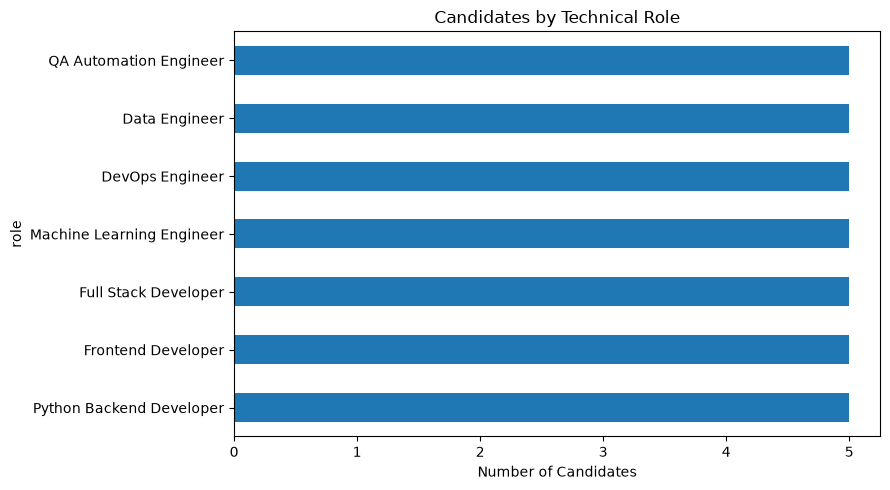

In [8]:

assert len(candidates) == 35
assert len(jobs) == 5

candidate_ids = {
    candidate["candidate_id"]
    for candidate in candidates
}

assert len(candidate_ids) == 35

for job in jobs:
    judgments = labels[job["job_id"]]["judgments"]

    assert len(judgments) == 35
    assert {
        item["candidate_id"] for item in judgments
    } == candidate_ids

print("Dataset validation passed.")

df_candidates = pd.DataFrame(candidates)

df_candidates["file_type"] = df_candidates[
    "resume_path"
].apply(lambda path: Path(path).suffix.lower())

df_candidates["skill_count"] = df_candidates[
    "skills"
].apply(len)

display(
    df_candidates[
        [
            "candidate_id",
            "candidate_name",
            "role",
            "experience_years",
            "skill_count",
            "file_type"
        ]
    ].head(10)
)

file_counts = (
    df_candidates["file_type"]
    .value_counts()
    .reindex([".pdf", ".docx", ".txt"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    file_counts.index,
    file_counts.values
)

ax.bar_label(bars)

ax.set_title("Resume Distribution by File Type")
ax.set_xlabel("File Type")
ax.set_ylabel("Number of Resumes")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))

experience_counts = (
    df_candidates["experience_years"]
    .value_counts()
    .sort_index()
)

ax.bar(
    experience_counts.index.astype(str),
    experience_counts.values
)

ax.set_title("Candidate Experience Distribution")
ax.set_xlabel("Years of Experience")
ax.set_ylabel("Number of Candidates")

plt.tight_layout()
plt.show()

role_counts = df_candidates["role"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))

role_counts.sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Candidates by Technical Role")
ax.set_xlabel("Number of Candidates")

plt.tight_layout()
plt.show()



### Dataset Observations

The synthetic dataset covers seven technical roles and
three resume formats.

The dataset contains multiple experience levels, allowing
the matching system to be tested against minimum-experience
requirements.

Because the resumes were generated from structured
templates, the dataset has more consistent formatting
than a typical collection of real-world resumes.


In [9]:

from resume_rag import ResumeRAG

rag = ResumeRAG(
    resume_folder=str(DATASET_DIR / "resumes")
)

documents = rag.load_resumes()

print("Resumes successfully loaded:", len(documents))

assert len(documents) == 35, (
    f"Expected 35 resumes, found {len(documents)}"
)


Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

E:\RAG_Profile_Matching\embeddings\embedding_service.py:19: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Model loaded successfully!
Embedding dimension: 384
ChromaDB location: E:\RAG_Profile_Matching\chroma_db
Collection: synthetic_resume_chunks

Scanning folder: E:\RAG_Profile_Matching\dataset\resumes
Milestone 1 list_files result: [{'name': 'C001_python_backend_developer.pdf', 'path': 'E:\\RAG_Profile_Matching\\dataset\\resumes\\C001_python_backend_developer.pdf', 'extension': '.pdf', 'size_bytes': 2174, 'modified_date': '2026-10-19T00:46:26'}, {'name': 'C002_python_backend_developer.pdf', 'path': 'E:\\RAG_Profile_Matching\\dataset\\resumes\\C002_python_backend_developer.pdf', 'extension': '.pdf', 'size_bytes': 2188, 'modified_date': '2026-10-19T00:46:26'}, {'name': 'C003_python_backend_developer.pdf', 'path': 'E:\\RAG_Profile_Matching\\dataset\\resumes\\C003_python_backend_developer.pdf', 'extension': '.pdf', 'size_bytes': 2182, 'modified_date': '2026-10-19T00:46:26'}, {'name': 'C004_python_backend_developer.pdf', 'path': 'E:\\RAG_Profile_Matching\\dataset\\resumes\\C004_python_backend

In [10]:

candidate_lookup = {
    candidate["candidate_id"]: candidate
    for candidate in candidates
}

metadata_rows = []

for document in documents:
    filename = Path(document["resume_path"]).name
    candidate_id = filename.split("_", 1)[0]

    expected = candidate_lookup[candidate_id]
    extracted = document["metadata"]

    extracted_skills = {
        skill.casefold()
        for skill in (extracted.get("skills") or [])
    }

    expected_skills = {
        skill.casefold()
        for skill in expected["skills"]
    }

    metadata_rows.append({
        "candidate_id": candidate_id,
        "name_correct": (
            str(extracted.get("candidate_name") or "")
            .strip().casefold()
            == expected["candidate_name"].casefold()
        ),
        "experience_correct": (
            extracted.get("experience_years")
            == expected["experience_years"]
        ),
        "skills_recalled": len(
            extracted_skills & expected_skills
        ),
        "expected_skills": len(expected_skills),
        "skill_recall": (
            len(extracted_skills & expected_skills)
            / len(expected_skills)
        )
    })

df_metadata = pd.DataFrame(metadata_rows)

display(df_metadata.head(10))

print(
    "Name extraction accuracy:",
    round(df_metadata["name_correct"].mean(), 4)
)

print(
    "Experience extraction accuracy:",
    round(df_metadata["experience_correct"].mean(), 4)
)

print(
    "Average skill recall:",
    round(df_metadata["skill_recall"].mean(), 4)
)


,candidate_id,name_correct,experience_correct,skills_recalled,expected_skills,skill_recall
0,C001,True,True,5,5,1.000000
1,C002,True,True,5,6,0.833333
2,C003,True,True,6,7,0.857143
3,C004,True,True,6,7,0.857143
4,C005,True,True,7,8,0.875000
5,C006,True,True,3,6,0.500000
6,C007,True,True,3,7,0.428571
7,C008,True,True,3,8,0.375000
8,C009,True,True,4,8,0.500000
9,C010,True,True,5,9,0.555556


Name extraction accuracy: 1.0
Experience extraction accuracy: 1.0
Average skill recall: 0.6586


In [11]:

chunks = rag.create_chunks()

print("Total chunks:", len(chunks))
print(
    "Average chunks per resume:",
    round(len(chunks) / len(documents), 2)
)


Created 6 chunks from C001_python_backend_developer.pdf
Created 6 chunks from C002_python_backend_developer.pdf
Created 6 chunks from C003_python_backend_developer.pdf
Created 6 chunks from C004_python_backend_developer.pdf
Created 6 chunks from C005_python_backend_developer.pdf
Created 6 chunks from C006_frontend_developer.pdf
Created 6 chunks from C007_frontend_developer.pdf
Created 6 chunks from C008_frontend_developer.pdf
Created 6 chunks from C009_frontend_developer.pdf
Created 6 chunks from C010_frontend_developer.pdf
Created 6 chunks from C011_full_stack_developer.pdf
Created 6 chunks from C012_full_stack_developer.pdf
Created 6 chunks from C013_full_stack_developer.pdf
Created 6 chunks from C014_full_stack_developer.pdf
Created 6 chunks from C015_full_stack_developer.pdf
Created 6 chunks from C016_machine_learning_engineer.docx
Created 6 chunks from C017_machine_learning_engineer.docx
Created 6 chunks from C018_machine_learning_engineer.docx
Created 6 chunks from C019_machine_l

In [12]:

chunk_rows = []

for chunk in chunks:
    chunk_rows.append({
        "candidate_id": (
            Path(chunk["resume_path"]).name
            .split("_", 1)[0]
        ),
        "section": chunk["section"],
        "characters": len(chunk["text"]),
        "words": len(chunk["text"].split())
    })

df_chunks = pd.DataFrame(chunk_rows)

display(df_chunks.head(10))
display(df_chunks[["characters", "words"]].describe())


,candidate_id,section,characters,words
0,C001,General,34,5
1,C001,Summary,127,16
2,C001,Skills,33,5
3,C001,Experience,193,26
4,C001,Projects,127,16
5,C001,Education,25,4
6,C002,General,37,5
7,C002,Summary,127,16
8,C002,Skills,48,7
9,C002,Experience,208,28


,characters,words
count,210.000000,210.000000
mean,94.323810,11.980952
std,66.006234,8.374010
min,3.000000,1.000000
25%,31.000000,5.000000
50%,95.500000,10.500000
75%,128.000000,16.000000
max,238.000000,30.000000


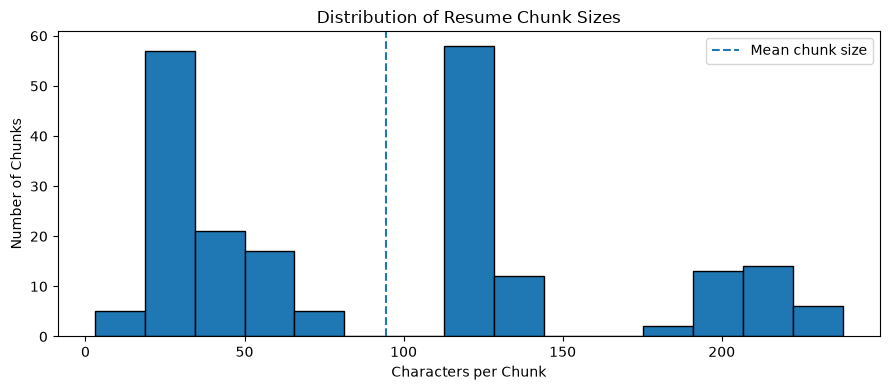

In [13]:

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    df_chunks["characters"],
    bins=15,
    edgecolor="black"
)

ax.axvline(
    df_chunks["characters"].mean(),
    linestyle="--",
    label="Mean chunk size"
)

ax.set_title("Distribution of Resume Chunk Sizes")
ax.set_xlabel("Characters per Chunk")
ax.set_ylabel("Number of Chunks")
ax.legend()

plt.tight_layout()
plt.show()


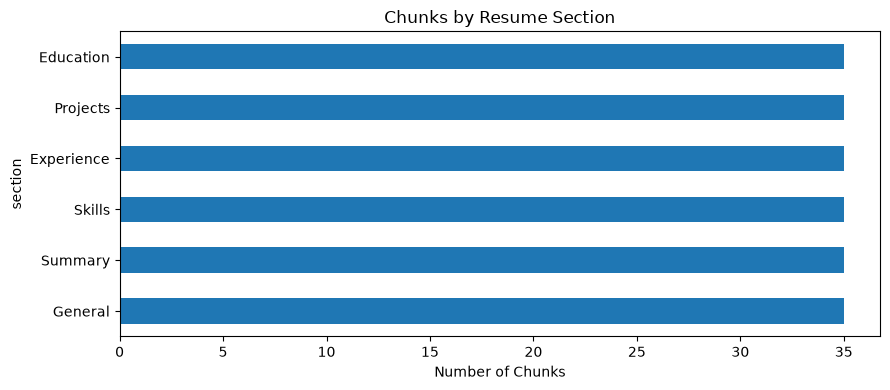

In [14]:

section_counts = df_chunks["section"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))

section_counts.sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Chunks by Resume Section")
ax.set_xlabel("Number of Chunks")

plt.tight_layout()
plt.show()


In [15]:

chunks_per_resume = (
    df_chunks.groupby("candidate_id")
    .size()
    .sort_values(ascending=False)
)

display(
    chunks_per_resume
    .rename("chunk_count")
    .reset_index()
)

print(
    "Minimum chunks:",
    chunks_per_resume.min()
)

print(
    "Maximum chunks:",
    chunks_per_resume.max()
)


,candidate_id,chunk_count
0,C001,6
1,C002,6
2,C003,6
3,C004,6
4,C005,6
5,C006,6
6,C007,6
7,C008,6
8,C009,6
9,C010,6


Minimum chunks: 6
Maximum chunks: 6



### Chunking Analysis

The chunking experiment examines the number and size
of passages generated from the resumes.

Section-aware chunking helps preserve contextual
information such as Skills, Experience, Projects,
and Education.

Key observations:
- Total chunks: [measured value]
- Average chunk size: [measured value]
- Average chunks per resume: [measured value]
- Most common chunk section: [measured value]

A limitation is that small resume sections may not
require chunk overlap, while large sections may need
additional splitting.


In [16]:

from embeddings.embedding_service import EmbeddingService

embedding_service = EmbeddingService()

sample_profiles = [
    "Python developer building FastAPI REST services",
    "Backend engineer creating Python web APIs",
    "React frontend developer building user interfaces",
    "Machine learning engineer training prediction models",
    "DevOps engineer deploying Docker Kubernetes workloads"
]

vectors = np.asarray(
    embedding_service.generate_embeddings(sample_profiles)
)

print("Embedding matrix shape:", vectors.shape)
print("Embedding dimension:", vectors.shape[1])


Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded successfully!
Embedding dimension: 384


E:\RAG_Profile_Matching\embeddings\embedding_service.py:19: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix shape: (5, 384)
Embedding dimension: 384


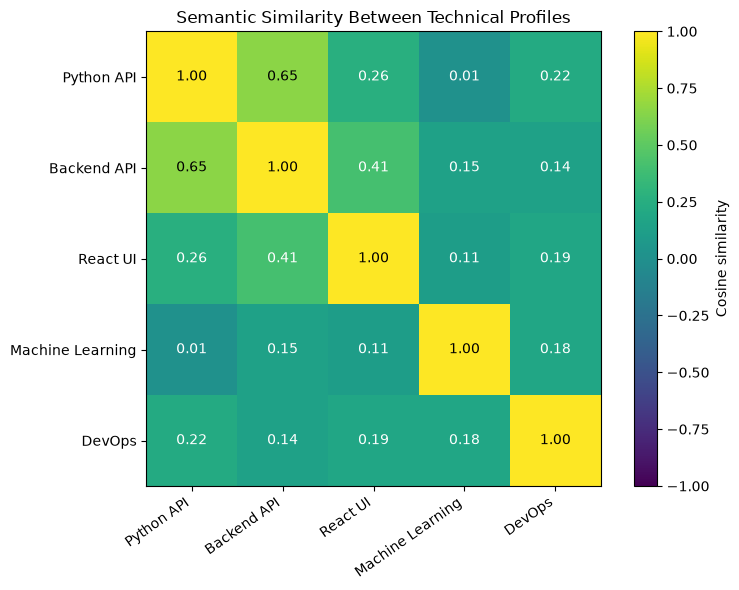

In [17]:

from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(vectors)

short_labels = [
    "Python API",
    "Backend API",
    "React UI",
    "Machine Learning",
    "DevOps"
]

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    similarities,
    cmap="viridis",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))

ax.set_xticklabels(
    short_labels,
    rotation=35,
    ha="right"
)

ax.set_yticklabels(short_labels)

for i in range(len(short_labels)):
    for j in range(len(short_labels)):
        ax.text(
            j, i,
            f"{similarities[i, j]:.2f}",
            ha="center",
            va="center",
            color="white" if similarities[i, j] < 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Cosine similarity")

ax.set_title("Semantic Similarity Between Technical Profiles")

plt.tight_layout()
plt.show()


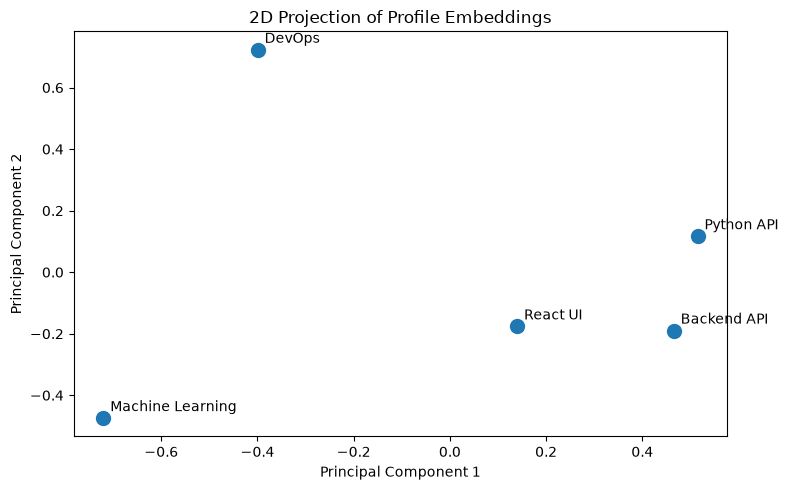

In [18]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

coordinates = pca.fit_transform(vectors)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    s=100
)

for i, label in enumerate(short_labels):
    ax.annotate(
        label,
        (coordinates[i, 0], coordinates[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title("2D Projection of Profile Embeddings")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


In [19]:

df_jobs = pd.DataFrame(jobs)

display(
    df_jobs[
        [
            "job_id",
            "title",
            "must_have_skills",
            "preferred_skills",
            "min_experience"
        ]
    ]
)


,job_id,title,must_have_skills,preferred_skills,min_experience
0,JD001,Python Backend Developer,"[Python, FastAPI]","[PostgreSQL, Docker, AWS]",5
1,JD002,Frontend Developer,"[React, JavaScript]","[TypeScript, Angular, Jest]",3
2,JD003,Full Stack Developer,"[Python, React, SQL]","[FastAPI, Docker, AWS]",4
3,JD004,Machine Learning Engineer,"[Python, Machine Learning]","[PyTorch, TensorFlow, AWS]",3
4,JD005,DevOps Engineer,"[Docker, Kubernetes, AWS]","[Terraform, Jenkins, Linux]",4


In [20]:

from retrieval.semantic_retriever import SemanticRetriever
from job_matcher import JobMatcher

retriever = SemanticRetriever()
matcher = JobMatcher()

job = next(
    item for item in jobs
    if item["job_id"] == "JD001"
)

semantic_candidates = retriever.search_candidates(
    job_description=job["job_description"],
    retrieve_all=True
)

hybrid_results = matcher.match_candidates(
    job_description=job["job_description"],
    must_have_skills=job["must_have_skills"],
    preferred_skills=job["preferred_skills"],
    min_experience=job["min_experience"],
    top_n=10
)

print("Job:", job["title"])
print("Semantic candidates:", len(semantic_candidates))
print("Hybrid eligible:", hybrid_results["eligible_count"])
print("Hybrid rejected:", hybrid_results["rejected_count"])


Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

E:\RAG_Profile_Matching\embeddings\embedding_service.py:19: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Model loaded successfully!
Embedding dimension: 384
ChromaDB location: E:\RAG_Profile_Matching\chroma_db
Collection: synthetic_resume_chunks
Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

E:\RAG_Profile_Matching\embeddings\embedding_service.py:19: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Model loaded successfully!
Embedding dimension: 384
ChromaDB location: E:\RAG_Profile_Matching\chroma_db
Collection: synthetic_resume_chunks
Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

E:\RAG_Profile_Matching\embeddings\embedding_service.py:19: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Model loaded successfully!
Embedding dimension: 384
ChromaDB location: E:\RAG_Profile_Matching\chroma_db
Collection: synthetic_resume_chunks

Generating job description embedding...
Searching ChromaDB...

Generating job description embedding...
Searching ChromaDB...
Job: Python Backend Developer
Semantic candidates: 35
Hybrid eligible: 5
Hybrid rejected: 30


In [21]:

def candidate_id_from_path(path):
    return (
        str(path).replace("\\", "/")
        .split("/")[-1]
        .split("_", 1)[0]
    )


semantic_rows = [
    {
        "rank": rank,
        "candidate_id": candidate_id_from_path(
            candidate["resume_path"]
        ),
        "candidate_name": candidate["candidate_name"],
        "score": round(candidate["semantic_score"], 4)
    }
    for rank, candidate in enumerate(
        semantic_candidates[:10], start=1
    )
]

hybrid_rows = [
    {
        "rank": rank,
        "candidate_id": candidate_id_from_path(
            candidate["resume_path"]
        ),
        "candidate_name": candidate["candidate_name"],
        "score": candidate["match_score"]
    }
    for rank, candidate in enumerate(
        hybrid_results["top_matches"], start=1
    )
]

df_semantic_top = pd.DataFrame(semantic_rows)
df_hybrid_top = pd.DataFrame(hybrid_rows)

print("Semantic-only ranking")
display(df_semantic_top)

print("Hybrid ranking")
display(df_hybrid_top)


Semantic-only ranking


,rank,candidate_id,candidate_name,score
0,1,C005,Kabir Mehta,0.8150
1,2,C002,Ananya Singh,0.7961
2,3,C003,Rohan Joshi,0.7801
3,4,C004,Priya Gupta,0.7698
4,5,C001,Aarav Rao,0.7384
5,6,C030,Diya Sharma,0.7033
6,7,C027,Vikram Verma,0.6719
7,8,C015,Diya Mehta,0.6685
8,9,C026,Neha Patel,0.6581
9,10,C014,Nikhil Gupta,0.6556


Hybrid ranking


,rank,candidate_id,candidate_name,score
0,1,C005,Kabir Mehta,92.60
1,2,C003,Rohan Joshi,77.87
2,3,C004,Priya Gupta,77.46
3,4,C015,Diya Mehta,73.41
4,5,C014,Nikhil Gupta,72.89


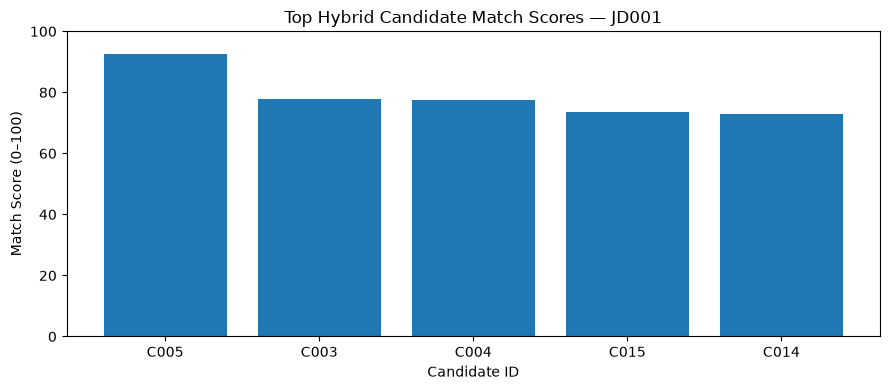

In [22]:

if not df_hybrid_top.empty:
    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        df_hybrid_top["candidate_id"],
        df_hybrid_top["score"]
    )

    ax.set_title("Top Hybrid Candidate Match Scores — JD001")
    ax.set_xlabel("Candidate ID")
    ax.set_ylabel("Match Score (0–100)")
    ax.set_ylim(0, 100)

    plt.tight_layout()
    plt.show()


In [23]:

rejected = hybrid_results["rejected_candidates"]

df_rejected = pd.DataFrame(rejected)

if not df_rejected.empty:
    available_columns = [
        column for column in [
            "candidate_name",
            "missing_must_have",
            "experience_eligible",
            "reasons"
        ]
        if column in df_rejected.columns
    ]

    display(df_rejected[available_columns].head(10))
else:
    print("No candidates were rejected.")


,candidate_name,missing_must_have,experience_eligible,reasons
0,Ananya Singh,[],False,[Experience 4.0 years is below required 5.0 ye...
1,Aarav Rao,[],False,[Experience 2.0 years is below required 5.0 ye...
2,Diya Sharma,[FastAPI],True,[Mandatory skills not evidenced: FastAPI]
3,Vikram Verma,[FastAPI],False,"[Mandatory skills not evidenced: FastAPI, Expe..."
4,Neha Patel,[FastAPI],False,"[Mandatory skills not evidenced: FastAPI, Expe..."
5,Tara Joshi,[FastAPI],True,[Mandatory skills not evidenced: FastAPI]
6,Vikram Singh,[],False,[Experience 4.0 years is below required 5.0 ye...
7,Kabir Mehta,[FastAPI],True,[Mandatory skills not evidenced: FastAPI]
8,Kabir Sharma,[FastAPI],True,[Mandatory skills not evidenced: FastAPI]
9,Nikhil Nair,[FastAPI],True,[Mandatory skills not evidenced: FastAPI]


In [24]:

performance_report = read_json(
    RESULTS_DIR / "performance_metrics.json"
)

df_per_job = pd.read_csv(
    RESULTS_DIR / "per_job_metrics.csv"
)

df_summary = pd.read_csv(
    RESULTS_DIR / "summary_metrics.csv"
)

print("Evaluation configuration:")
display(pd.DataFrame(
    [performance_report["configuration"]]
))

print("Summary metrics:")
display(df_summary)


Evaluation configuration:


,repetitions,warmups,cutoffs,semantic_retrieve_all,hybrid_top_n
0,30,2,"[5, 10]",True,35


Summary metrics:


,method,jobs_evaluated,precision_at_5,recall_at_5,hit_rate_at_5,precision_at_10,recall_at_10,hit_rate_at_10,mean_ms,median_ms,p95_ms,mrr
0,semantic_only,5,0.76,0.820,1,0.5,1.0,1,44.1114,40.5566,74.3678,1.0
1,hybrid,5,0.88,0.925,1,0.5,1.0,1,42.7294,39.2412,62.7384,1.0


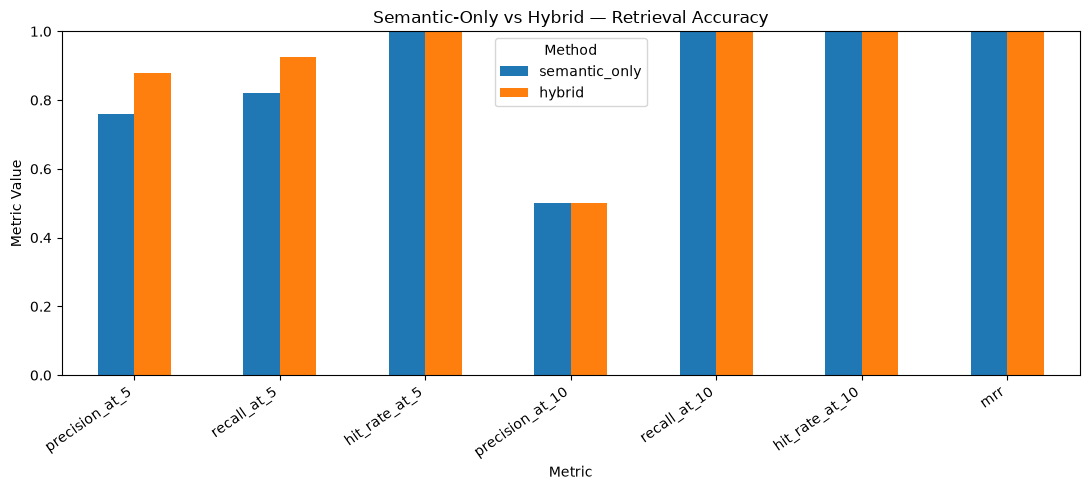

In [25]:

accuracy_columns = [
    "precision_at_5",
    "recall_at_5",
    "hit_rate_at_5",
    "precision_at_10",
    "recall_at_10",
    "hit_rate_at_10",
    "mrr"
]

accuracy_comparison = (
    df_summary.set_index("method")[accuracy_columns]
)

ax = accuracy_comparison.T.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Semantic-Only vs Hybrid — Retrieval Accuracy")
ax.set_ylabel("Metric Value")
ax.set_ylim(0, 1)
ax.set_xlabel("Metric")

plt.xticks(rotation=35, ha="right")
plt.legend(title="Method")
plt.tight_layout()
plt.show()


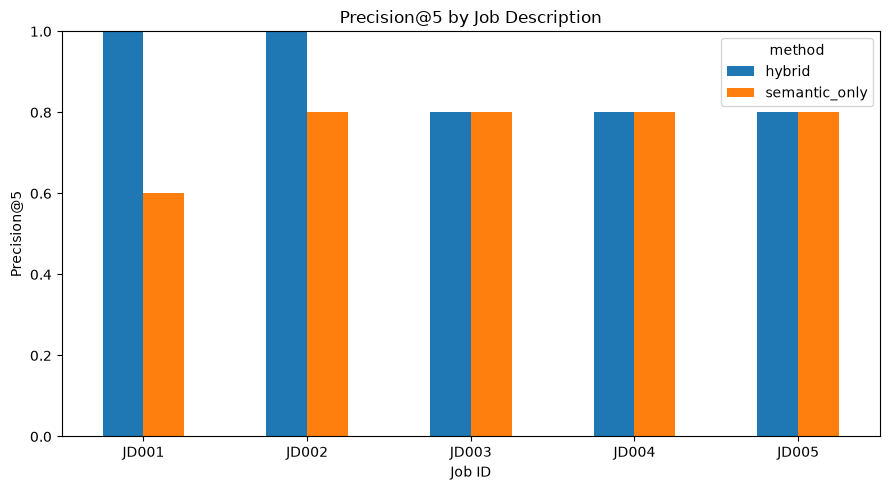

In [26]:

precision_by_job = df_per_job.pivot(
    index="job_id",
    columns="method",
    values="precision_at_5"
)

ax = precision_by_job.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Precision@5 by Job Description")
ax.set_xlabel("Job ID")
ax.set_ylabel("Precision@5")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


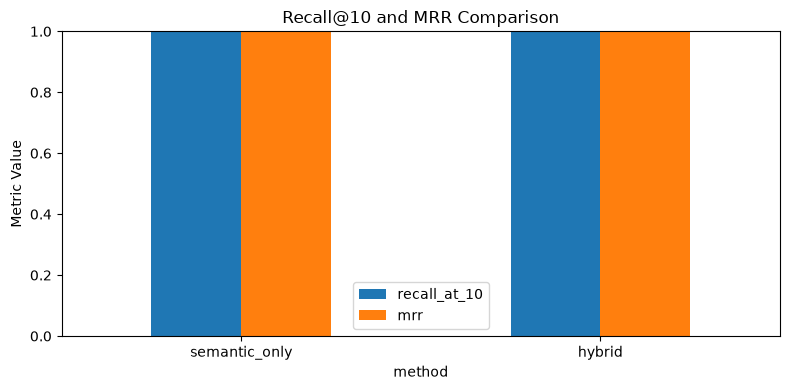

In [27]:

selected_metrics = (
    df_summary.set_index("method")[
        ["recall_at_10", "mrr"]
    ]
)

ax = selected_metrics.plot(
    kind="bar",
    figsize=(8, 4)
)

ax.set_title("Recall@10 and MRR Comparison")
ax.set_ylabel("Metric Value")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


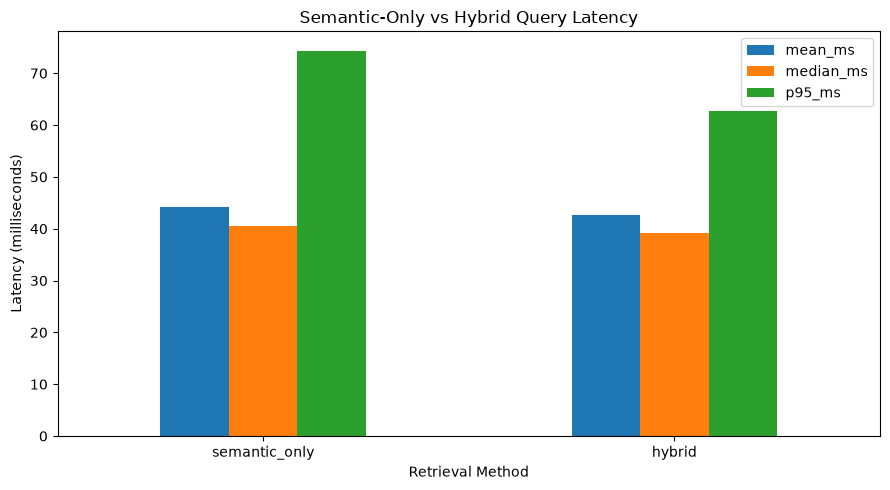

In [28]:

latency_columns = [
    "mean_ms",
    "median_ms",
    "p95_ms"
]

latency_comparison = (
    df_summary.set_index("method")[latency_columns]
)

ax = latency_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Semantic-Only vs Hybrid Query Latency")
ax.set_xlabel("Retrieval Method")
ax.set_ylabel("Latency (milliseconds)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [29]:

display_columns = [
    "method",
    "precision_at_5",
    "recall_at_5",
    "precision_at_10",
    "recall_at_10",
    "mrr",
    "mean_ms",
    "p95_ms"
]

display(
    df_summary[display_columns].round(4)
)


,method,precision_at_5,recall_at_5,precision_at_10,recall_at_10,mrr,mean_ms,p95_ms
0,semantic_only,0.76,0.820,0.5,1.0,1.0,44.1114,74.3678
1,hybrid,0.88,0.925,0.5,1.0,1.0,42.7294,62.7384


In [30]:

ranking_lookup = {
    (item["job_id"], item["method"]): item["candidate_ids"]
    for item in performance_report["rankings"]
}

failure_rows = []

for job in jobs:
    job_id = job["job_id"]

    relevant = {
        judgment["candidate_id"]
        for judgment in labels[job_id]["judgments"]
        if judgment["relevant"]
    }

    for method in ["semantic_only", "hybrid"]:
        ranking = ranking_lookup[(job_id, method)]
        top_10 = set(ranking[:10])

        false_positives = top_10 - relevant
        missed_relevant = relevant - top_10

        failure_rows.append({
            "job_id": job_id,
            "method": method,
            "false_positives_at_10": len(false_positives),
            "missed_relevant_at_10": len(missed_relevant),
            "false_positive_ids": sorted(false_positives),
            "missed_candidate_ids": sorted(missed_relevant)
        })

df_failures = pd.DataFrame(failure_rows)

display(df_failures)


,job_id,method,false_positives_at_10,missed_relevant_at_10,false_positive_ids,missed_candidate_ids
0,JD001,semantic_only,5,0,"[C001, C002, C026, C027, C030]",[]
1,JD001,hybrid,0,0,[],[]
2,JD002,semantic_only,2,0,"[C006, C011]",[]
3,JD002,hybrid,0,0,[],[]
4,JD003,semantic_only,6,0,"[C002, C003, C005, C011, C027, C030]",[]
5,JD003,hybrid,0,0,[],[]
6,JD004,semantic_only,6,0,"[C016, C026, C027, C028, C029, C030]",[]
7,JD004,hybrid,0,0,[],[]
8,JD005,semantic_only,6,0,"[C020, C021, C026, C027, C030, C035]",[]
9,JD005,hybrid,0,0,[],[]


,false_positives_at_10,missed_relevant_at_10
method,,
hybrid,0,0
semantic_only,25,0


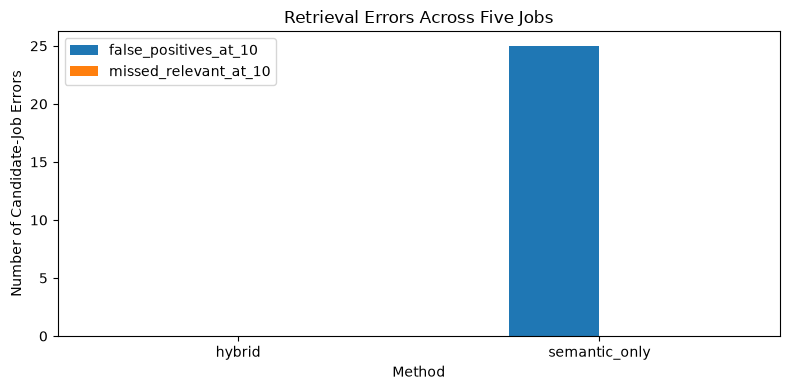

In [31]:

failure_summary = (
    df_failures.groupby("method")[
        [
            "false_positives_at_10",
            "missed_relevant_at_10"
        ]
    ]
    .sum()
)

display(failure_summary)

ax = failure_summary.plot(
    kind="bar",
    figsize=(8, 4)
)

ax.set_title("Retrieval Errors Across Five Jobs")
ax.set_xlabel("Method")
ax.set_ylabel("Number of Candidate-Job Errors")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:

missed_examples = df_failures[
    df_failures["missed_relevant_at_10"] > 0
]

if not missed_examples.empty:
    example = missed_examples.iloc[0]

    job_id = example["job_id"]
    candidate_id = example["missed_candidate_ids"][0]

    candidate = next(
        item for item in candidates
        if item["candidate_id"] == candidate_id
    )

    print("Job:", job_id)
    print("Method:", example["method"])
    print("Missed candidate:", candidate["candidate_name"])
    print("Role:", candidate["role"])
    print("Skills:", candidate["skills"])
    print("Experience:", candidate["experience_years"])
else:
    print("No missed relevant candidates in top-10 evaluation.")


No missed relevant candidates in top-10 evaluation.



# Final Experimental Findings

## 1. Dataset Summary

The experiments used 35 synthetic resumes covering seven
technical roles and five job descriptions.

Each candidate-job pair had a ground-truth relevance
judgment, producing 175 judgments in total.

## 2. Parsing and Chunking

- Resumes successfully loaded: [value]
- Total generated chunks: [value]
- Average chunks per resume: [value]
- Name extraction accuracy: [value]
- Experience extraction accuracy: [value]
- Average skill recall: [value]

## 3. Embedding Experiment

The sentence embedding model generated 384-dimensional
vectors.

The semantic similarity experiment compared descriptions
of related and unrelated technical roles.

Observed behavior: [describe actual similarity results].

## 4. Retrieval Accuracy

| Metric | Semantic-only | Hybrid |
|---|---|---|
| Precision@5 | [value] | [value] |
| Recall@5 | [value] | [value] |
| Precision@10 | [value] | [value] |
| Recall@10 | [value] | [value] |
| Hit Rate@5 | [value] | [value] |
| MRR | [value] | [value] |

Explain which method performed better and why.

## 5. Latency

| Metric | Semantic-only | Hybrid |
|---|---|---|
| Mean latency (ms) | [value] | [value] |
| Median latency (ms) | [value] | [value] |
| Mean per-job P95 (ms) | [value] | [value] |

Discuss the trade-off between retrieval quality
and computational cost.

## 6. Failure Analysis

Describe at least one incorrectly retrieved candidate
and one missed relevant candidate, if present.

Explain possible causes using the extracted metadata,
candidate skills, and retrieved passages.

## 7. Limitations

1. The dataset is synthetic and template-generated.
2. Ground-truth labels use deterministic eligibility rules.
3. Semantic retrieval fetches all chunks for this benchmark.
4. Keyword matching may miss skill synonyms.
5. Metadata extraction relies on rule-based parsing.
6. The evaluation uses a small collection of resumes.

## 8. Future Improvements

- Introduce independently annotated relevance judgments.
- Add cross-encoder reranking.
- Evaluate retrieval at larger dataset sizes.
- Improve skill synonym handling.
- Compare multiple embedding models.
- Experiment with different chunk sizes and overlap.
- Add LLM-grounded explanations with source citations.

## Conclusion

[Write a concise conclusion supported by the
actual accuracy and latency results.]
